# Implied acuity distributions vs the recorded visits

Fitted model: `fit_person_eyes2d_ext.py asym+sig+near`, trace `person_eyes2d_asym_sig_near.nc`, the best fit so far. Ages 20–50, no interocular-difference filter, all three readings (left, right, binocular).

- Each eye has its own true acuity: a person value plus an eye difference of one of three kinds. Most people have near-identical eyes. A quarter have one eye about three letters worse, and a few have a large difference (mostly poor eyes). A small poor-vision component sits on top.
- Readings add test noise. Binocular is Ding & Sperling of the two eyes' true acuities, with γ and binocular noise changing with the better eye through a sigmoid.
- One recording rule for all three readings, with records from 20/15 to 20/400 and recording style (line-only or letters) set per visit.

Chains whose mean log density is more than 10 below the best chain are dropped first: one chain of 24 is stuck in a worse mode. Curves use posterior means.

**Empirical** means the numbers recorded at each visit. Recorded logMAR is discrete, so tall bars at 20/15, 20/20 and 20/25 are bare records stacked on one value. The model says those people are really spread around the line, so bars and curves are not expected to match bin by bin. The cumulative plots are the fairer comparison.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import expit

import fit_person_eyes2d_ext as ext
import fit_person_eyes2d_full as full
import fit_person_records as fpr
from fit_ding_sperling_decimal_pymc import load_all_df

OPTIONS = "asym+sig+near"
SURFACE, INK, MUTED, GRID_INK = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
EMPIRICAL, MODEL = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID_INK, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID_INK,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11,
    "figure.dpi": 110,
})

idata = az.from_netcdf("person_eyes2d_asym_sig_near.nc")
logp = idata.sample_stats["logp"].mean("draw").to_numpy()
keep = [int(c) for c, v in zip(idata.posterior.chain.values, logp) if v > logp.max() - 10]
print(f"chain mean log density: {np.round(logp, 1).tolist()}")
print(f"keeping {len(keep)} of {len(logp)} chains")
idata = idata.sel(chain=keep)
p = ext.post_means(idata, OPTIONS)
az.summary(idata, var_names=ext.names(OPTIONS), round_to=4)[["mean", "sd", "hdi_3%", "hdi_97%", "ess_bulk", "r_hat"]]

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`


WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


chain mean log density: [-14189.4, -14189.1, -14189.0, -14189.2, -14189.3, -14189.2, -14189.3, -14189.4, -14189.2, -14188.9, -14209.9, -14189.3, -14189.3, -14189.3, -14189.2, -14189.4, -14189.1, -14189.0, -14189.9, -14189.3, -14189.8, -14189.6, -14189.3, -14189.0]
keeping 23 of 24 chains


,mean,sd,hdi_3%,hdi_97%,ess_bulk,r_hat
mean_logmar,-0.0580,0.0025,-0.0628,-0.0534,4864.5815,1.0013
sd_logmar,0.0712,0.0024,0.0667,0.0756,4233.2499,1.0024
sigma_d,0.0084,0.0013,0.0059,0.0109,11721.0794,1.0015
u_eye,0.0569,0.0063,0.0454,0.0688,9302.6257,1.0009
sigma_d2,0.3619,0.0240,0.3169,0.4060,14443.8966,1.0022
sigma_test,0.0107,0.0006,0.0100,0.0118,9466.0164,1.0012
ds_eps,4.4049,0.1973,4.0337,4.7682,5229.5087,1.0021
p_line_style,0.3010,0.0108,0.2808,0.3211,16383.1992,1.0010
w_poor,0.0349,0.0066,0.0229,0.0473,10582.0705,1.0015
gap,0.1799,0.0642,0.1000,0.2982,7677.4522,1.0030


In [2]:
# Empirical records, one row per visit, the same rows as the fit.
df = load_all_df()
df = df[df["age"].between(fpr.AGE_LO, fpr.AGE_HI)]
cats = pd.DataFrame({"L": full.categorise(df["raw_left"], df["left"]),
                     "R": full.categorise(df["raw_right"], df["right"]),
                     "B": full.categorise(df["raw_both"], df["logmar_binocular"])})
keep_rows = cats.notna().all(axis=1)
df, cats = df[keep_rows], cats[keep_rows].astype(int)
n_visits = len(df)

empirical = {
    "Left eye": df["left"].to_numpy(),
    "Right eye": df["right"].to_numpy(),
    "Better eye": df["logmar_better"].to_numpy(),
    "Binocular": df["logmar_binocular"].to_numpy(),
}

# Implied readings before recording, and the records they produce.
sim = ext.simulate(p, 2_000_000, np.random.default_rng(1))
implied = {
    "Left eye": sim["y_l"].to_numpy(),
    "Right eye": sim["y_r"].to_numpy(),
    "Better eye": np.minimum(sim["y_l"], sim["y_r"]).to_numpy(),
    "Binocular": sim["y_b"].to_numpy(),
}
print(f"{n_visits} visits")
pd.DataFrame({
    "empirical mean": {k: v.mean() for k, v in empirical.items()},
    "implied mean": {k: v.mean() for k, v in implied.items()},
    "empirical median": {k: np.median(v) for k, v in empirical.items()},
    "implied median": {k: np.median(v) for k, v in implied.items()},
    "empirical SD": {k: v.std(ddof=1) for k, v in empirical.items()},
    "implied SD": {k: v.std(ddof=1) for k, v in implied.items()},
}).round(3)

sc file: kept 117 of 198 rows
nonint_age file: kept 132 of 133 rows (dash/dot ages with valid acuity)
Rows used: 7085 of 7085 (no logMAR cutoff needed)


3604 visits


,empirical mean,implied mean,empirical median,implied median,empirical SD,implied SD
Left eye,-0.016,-0.045,0.00,-0.050,0.113,0.132
Right eye,-0.017,-0.045,0.00,-0.050,0.114,0.133
Better eye,-0.033,-0.069,0.00,-0.066,0.092,0.129
Binocular,-0.048,-0.091,-0.06,-0.088,0.091,0.125


## Empirical counts with the implied distribution on top

Bars are recorded values per visit, in 0.02 logMAR bins (one letter). The curve is the implied reading before recording, scaled to expected visits per bin. Records beyond 0.35 logMAR are off the plot but counted.

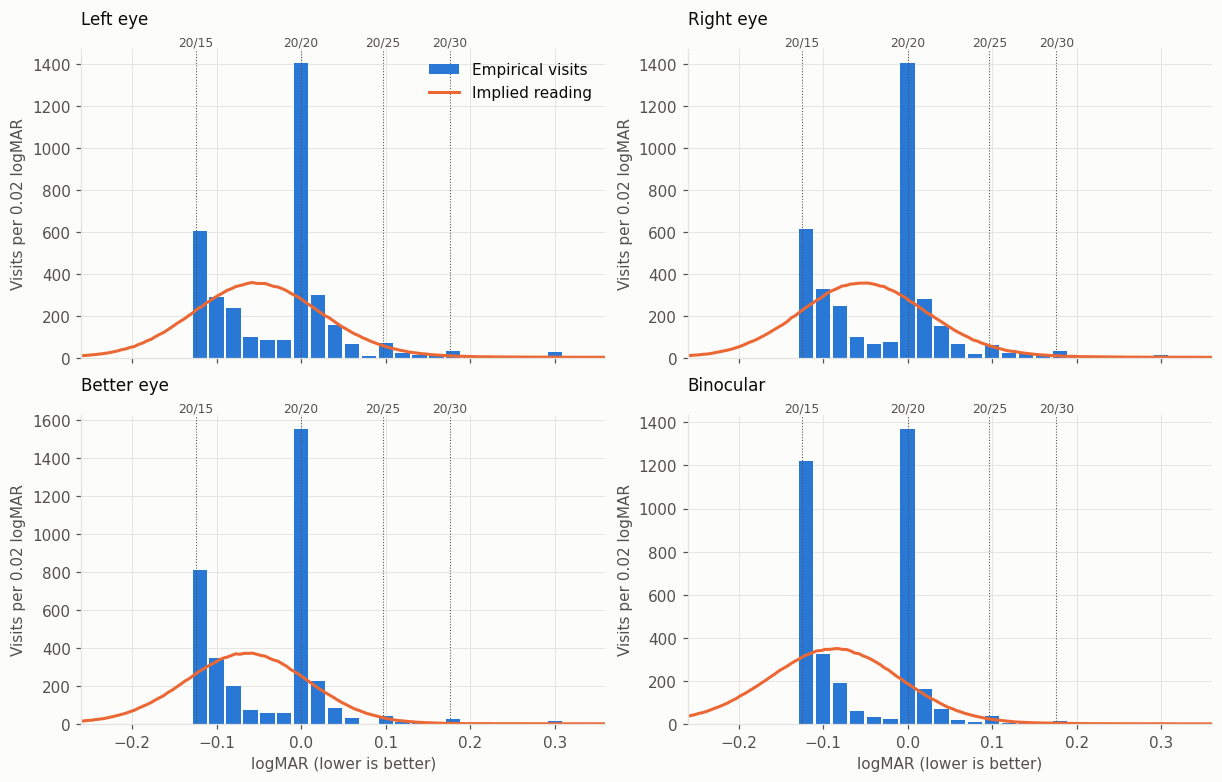

In [3]:
XLIM = (-0.26, 0.36)
LINES = {"20/15": fpr.L15, "20/20": fpr.L20, "20/25": fpr.L25, "20/30": fpr.L30}
BIN = 0.02
edges_ = np.arange(-0.31, 0.41, BIN)   # bins centred on 0, so records sit on their lines
fine = np.arange(-0.4, 0.5, 0.005)


def mark_lines(ax, labels=False):
    top = ax.get_ylim()[1]
    for name, x in LINES.items():
        ax.axvline(x, color=MUTED, lw=0.7, ls=":", zorder=1)
        if labels:
            ax.text(x, top, name, ha="center", va="bottom", fontsize=8, color=MUTED)


names = list(empirical)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, layout="constrained")
for ax, name in zip(axes.ravel(), names):
    ax.hist(empirical[name], bins=edges_, color=EMPIRICAL, rwidth=0.85, label="Empirical visits")
    dens, e = np.histogram(implied[name], bins=fine)
    ax.plot((e[1:] + e[:-1]) / 2, dens / len(implied[name]) / 0.005 * n_visits * BIN, color=MODEL, lw=2,
            label="Implied reading")
    ax.set_xlim(XLIM)
    ax.set_title(name, loc="left", pad=16)
    ax.set_ylabel("Visits per 0.02 logMAR")
    mark_lines(ax, labels=True)
axes[0, 0].legend(frameon=False, loc="upper right")
axes[1, 0].set_xlabel("logMAR (lower is better)")
axes[1, 1].set_xlabel("logMAR (lower is better)")
plt.show()

## Cumulative comparison

This removes the binning problem. Bare records pile up at a line, so the empirical curve jumps there. If bare records are people spread around the line, the jump should straddle the implied curve.

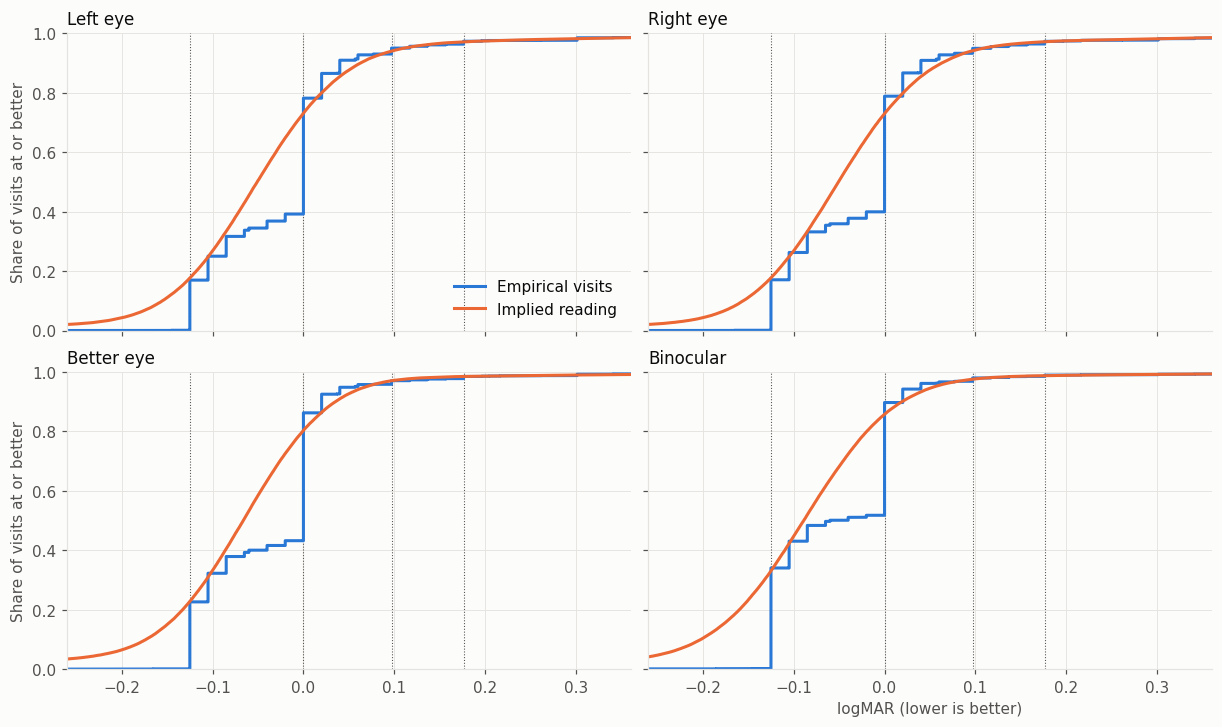

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True, sharey=True, layout="constrained")
for ax, name in zip(axes.ravel(), names):
    x = np.sort(empirical[name])
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=EMPIRICAL, lw=2, label="Empirical visits")
    z = np.sort(implied[name][::20])
    ax.plot(z, np.arange(1, len(z) + 1) / len(z), color=MODEL, lw=2, label="Implied reading")
    ax.set_xlim(XLIM)
    ax.set_ylim(0, 1.0)
    ax.set_title(name, loc="left")
    mark_lines(ax)
axes[0, 0].legend(frameon=False, loc="lower right")
axes[0, 0].set_ylabel("Share of visits at or better")
axes[1, 0].set_ylabel("Share of visits at or better")
axes[1, 1].set_xlabel("logMAR (lower is better)")
plt.show()

## Where each record type comes from

The implied reading before recording, split by the record the model expects it to produce, for eyes (left and right together) and for binocular. Each band's area is that record's expected share. The dashed lines mark the mean and ±1 SD of the implied readings of people outside the poor-vision component. That includes the few with a large eye difference, which widens the SD. The lower panel zooms in on 20/25.

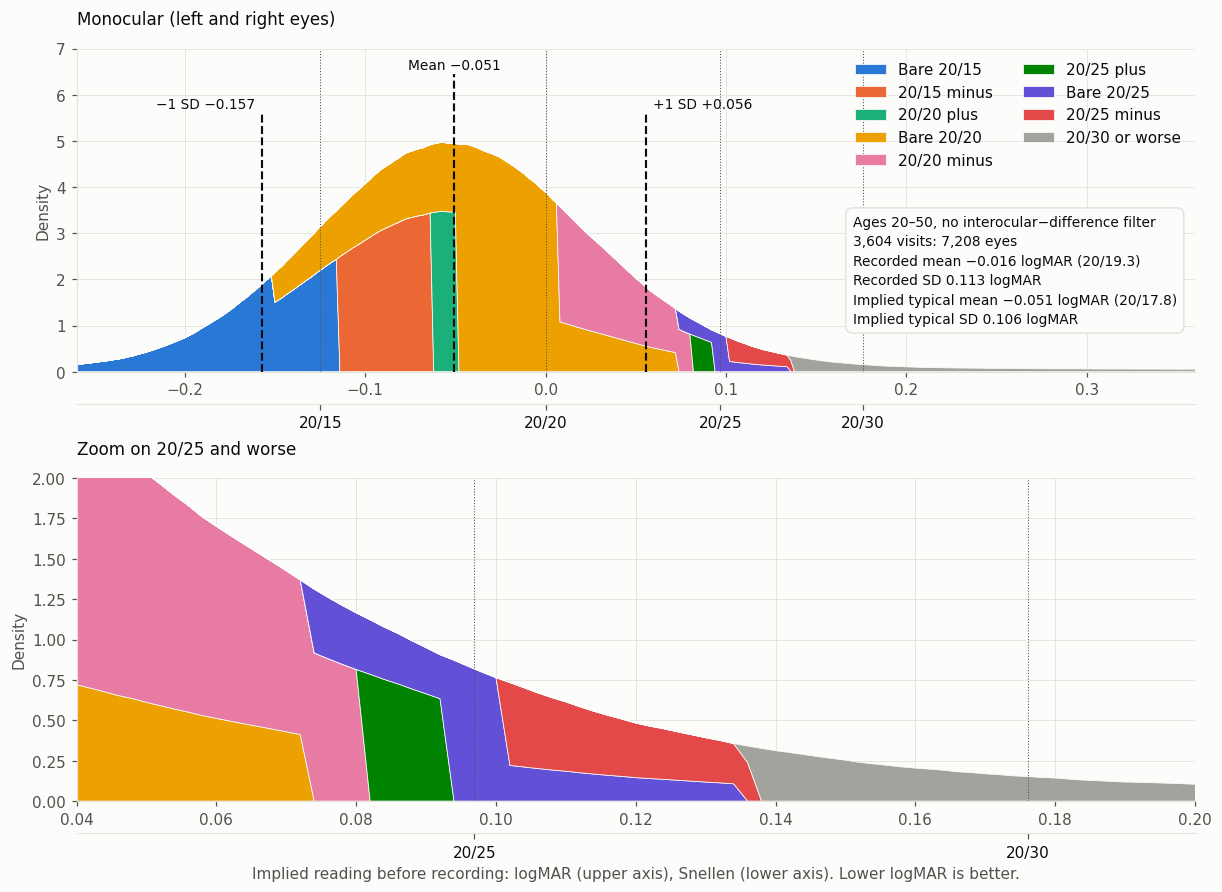

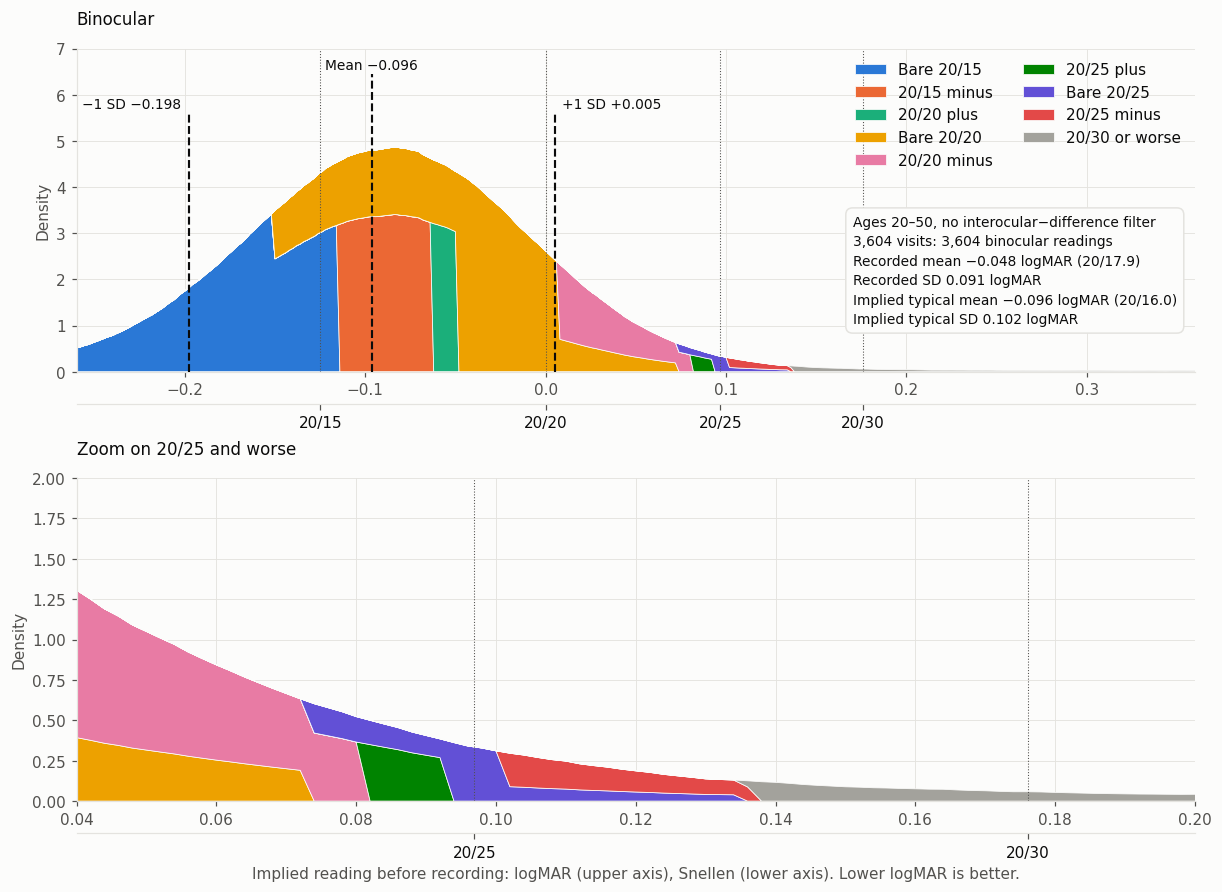

In [5]:
y = np.arange(-0.35, 0.4, 0.002)
labels = ["Bare 20/15", "20/15 minus", "20/20 plus", "Bare 20/20", "20/20 minus",
          "20/25 plus", "Bare 20/25", "20/25 minus", "20/30 or worse"]
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
          "#008300", "#6250d6", "#e34948", "#a3a29c"]
snellen = lambda logmar: f"20/{20 * 10 ** logmar:.1f}"
YMAX = 7.0


def density(x):
    # Smoothed histogram of simulated readings on the plotting grid.
    h, e = np.histogram(x, bins=np.r_[y - 0.001, y[-1] + 0.001])
    h = np.convolve(h, np.ones(5) / 5, mode="same")
    return h / len(x) / 0.002


def snellen_axis(ax, names, label=None):
    # Second x-axis below the logMAR axis, with a tick at each Snellen line.
    sec = ax.secondary_xaxis(-0.1)
    sec.set_xticks([LINES[n] for n in names], names)
    sec.tick_params(axis="x", length=4, labelcolor=INK)
    if label:
        sec.set_xlabel(label)


def record_types(title, readings, typical, recorded, count_line, stem):
    line_lo, line_hi, let_lo, let_hi = full.edges(p, np.array)
    pi = p["p_line_style"]
    share = lambda k: pi * ((y >= line_lo[k]) & (y < line_hi[k])) + (1 - pi) * ((y >= let_lo[k]) & (y < let_hi[k]))
    dens = density(readings)
    by_cat = [dens * share(k) for k in range(8)]
    by_cat.append(dens * sum(share(k) for k in range(8, len(full.CATS))))
    mean_typ, sd_typ = typical.mean(), typical.std()

    fig, axes = plt.subplots(2, 1, figsize=(11, 8), layout="constrained")
    for ax, xlim in zip(axes, [XLIM, (0.04, 0.2)]):
        ax.stackplot(y, by_cat, labels=labels, colors=colors, edgecolor=SURFACE, linewidth=0.5)
        ax.set_xlim(xlim)
        ax.set_ylabel("Density")
    axes[0].set_ylim(0, YMAX)
    axes[1].set_ylim(0, 2.0)
    axes[0].set_title(title, loc="left", pad=16)
    axes[1].set_title("Zoom on 20/25 and worse", loc="left", pad=16)
    label = "Implied reading before recording: logMAR (upper axis), Snellen (lower axis). Lower logMAR is better."
    snellen_axis(axes[0], list(LINES))
    snellen_axis(axes[1], ["20/25", "20/30"], label)
    axes[0].legend(frameon=False, ncol=2, loc="upper right")
    mark_lines(axes[0])
    for name in ["20/25", "20/30"]:
        axes[1].axvline(LINES[name], color=MUTED, lw=0.7, ls=":", zorder=4)

    for x, top, text, ha, dx in [(mean_typ, 6.45, f"Mean {mean_typ:+.3f}", "center", 0),
                                 (mean_typ - sd_typ, 5.6, f"−1 SD {mean_typ - sd_typ:+.3f}", "right", -0.004),
                                 (mean_typ + sd_typ, 5.6, f"+1 SD {mean_typ + sd_typ:+.3f}", "left", 0.004)]:
        axes[0].vlines(x, 0, top, color=INK, lw=1.4, ls="--", zorder=5)
        axes[0].text(x + dx, top + 0.05, text.replace("-", "−"), ha=ha, va="bottom", fontsize=9, color=INK)

    summary = "\n".join([
        f"Ages {fpr.AGE_LO}–{fpr.AGE_HI}, no interocular-difference filter",
        count_line,
        f"Recorded mean {recorded.mean():+.3f} logMAR ({snellen(recorded.mean())})",
        f"Recorded SD {recorded.std(ddof=1):.3f} logMAR",
        f"Implied typical mean {mean_typ:+.3f} logMAR ({snellen(mean_typ)})",
        f"Implied typical SD {sd_typ:.3f} logMAR",
    ]).replace("-", "−")
    axes[0].text(0.35, 3.4, summary, va="top", ha="right", multialignment="left", fontsize=9, color=INK,
                 linespacing=1.5, zorder=6,
                 bbox=dict(facecolor=SURFACE, edgecolor=GRID_INK, boxstyle="round,pad=0.5"))
    fig.savefig(f"{stem}.png", dpi=300)
    fig.savefig(f"{stem}.pdf")
    plt.show()


not_poor = ~sim["poor"].to_numpy()
eyes = np.r_[empirical["Left eye"], empirical["Right eye"]]
record_types("Monocular (left and right eyes)", np.r_[implied["Left eye"], implied["Right eye"]],
             np.r_[implied["Left eye"][not_poor], implied["Right eye"][not_poor]], eyes,
             f"{n_visits:,} visits: {len(eyes):,} eyes", "record_types_monocular")
record_types("Binocular", implied["Binocular"], implied["Binocular"][not_poor], empirical["Binocular"],
             f"{n_visits:,} visits: {n_visits:,} binocular readings", "record_types_binocular")

### What a bare record covers at each line

Windows are absolute logMAR, from the same fit, and the same for eyes and binocular. `NaN` means the window is open on that side, because the chart stops at 20/15.

In [6]:
def windows(r):
    return pd.DataFrame({
        "Letter visits, from": [None, -r["h20_better"], fpr.L25 - r["h25"]],
        "Letter visits, to": [fpr.L15 + r["h_bare"], r["h20_worse"], fpr.L25 + r["h25"]],
        "Line-only visits, from": [None, r["b1"], r["b2"]],
        "Line-only visits, to": [r["b1"], r["b2"], r["b3"]],
    }, index=["Bare 20/15", "Bare 20/20", "Bare 20/25"]).astype(float).round(3)


windows(p)

,"Letter visits, from","Letter visits, to","Line-only visits, from","Line-only visits, to"
Bare 20/15,NaN,-0.115,NaN,-0.150
Bare 20/20,-0.048,0.007,-0.150,0.073
Bare 20/25,0.092,0.102,0.073,0.136


## Empirical vs model record counts

Counts of each record type, compared with what the fitted model produces after recording. This is the direct test of the fit. Lines 20/30 to 20/400 are separate records in the model.

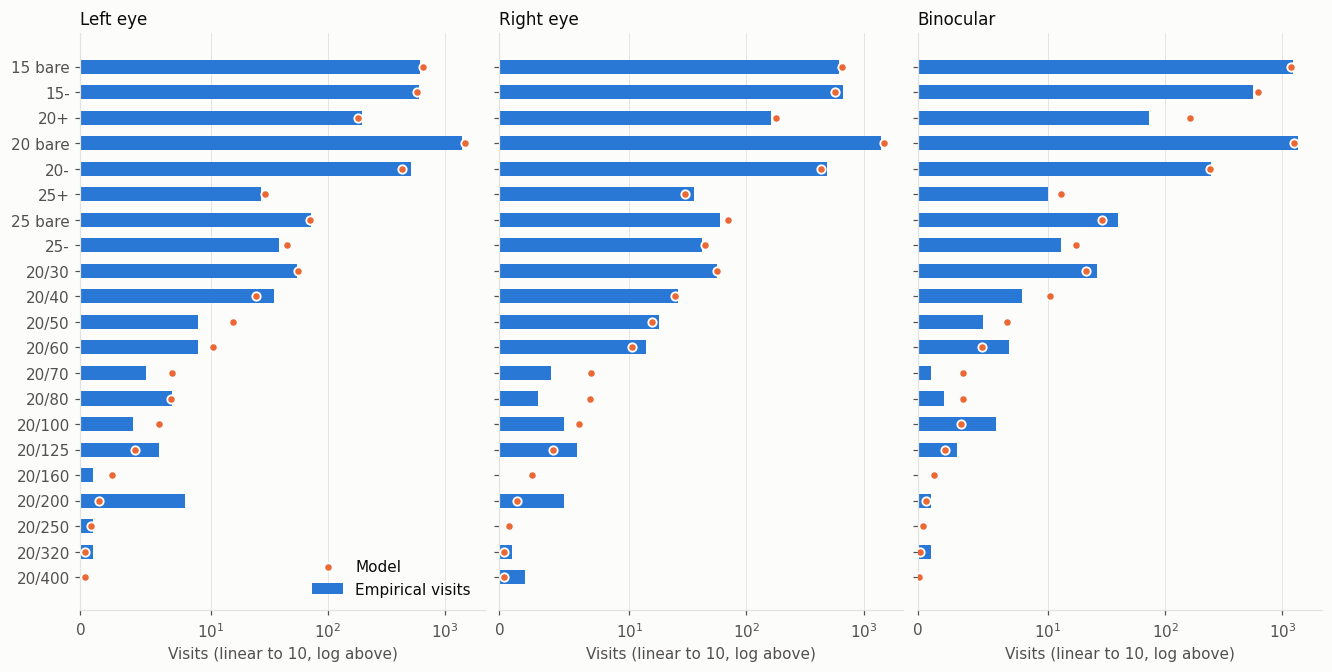

,L empirical,L model,R empirical,R model,B empirical,B model
15 bare,612,654,616,654,1227,1197
15-,605,572,661,573,566,624
20+,196,180,163,180,73,162
20 bare,1405,1489,1402,1487,1367,1263
20-,508,429,484,429,248,240
25+,27,29,36,30,10,13
25 bare,72,70,60,70,40,29
25-,38,45,42,45,13,17
20/30,55,56,56,56,26,21
20/40,35,25,26,25,8,10


In [7]:
scale = n_visits / len(sim)
k = range(len(full.CATS))
fig, axes = plt.subplots(1, 3, figsize=(12, 6), sharex=True, layout="constrained")
rows = []
for ax, (col, title) in zip(axes, [("L", "Left eye"), ("R", "Right eye"), ("B", "Binocular")]):
    o = cats[col].value_counts().reindex(k, fill_value=0).to_numpy()
    s = sim[col].value_counts().reindex(k, fill_value=0).to_numpy() * scale
    pos = np.arange(len(full.CATS))
    ax.barh(pos, o, height=0.55, color=EMPIRICAL, label="Empirical visits")
    ax.scatter(s, pos, s=30, color=MODEL, edgecolor=SURFACE, linewidth=1.2, zorder=3, label="Model")
    ax.set_xscale("symlog", linthresh=10)
    ax.set_yticks(pos, full.CATS if col == "L" else [""] * len(pos))
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Visits (linear to 10, log above)")
    rows.append(pd.Series(o, index=full.CATS, name=f"{col} empirical"))
    rows.append(pd.Series(s.round(0).astype(int), index=full.CATS, name=f"{col} model"))
axes[0].legend(frameon=False, loc="lower right")
plt.show()
pd.concat(rows, axis=1)

## Ding & Sperling sigmoid

γ and binocular noise against the better eye's true acuity, with the 94% posterior interval. The grey histogram shows where the better-eye records are: almost all are better than 20/30, so the low-vision half of the curve rests on few people.

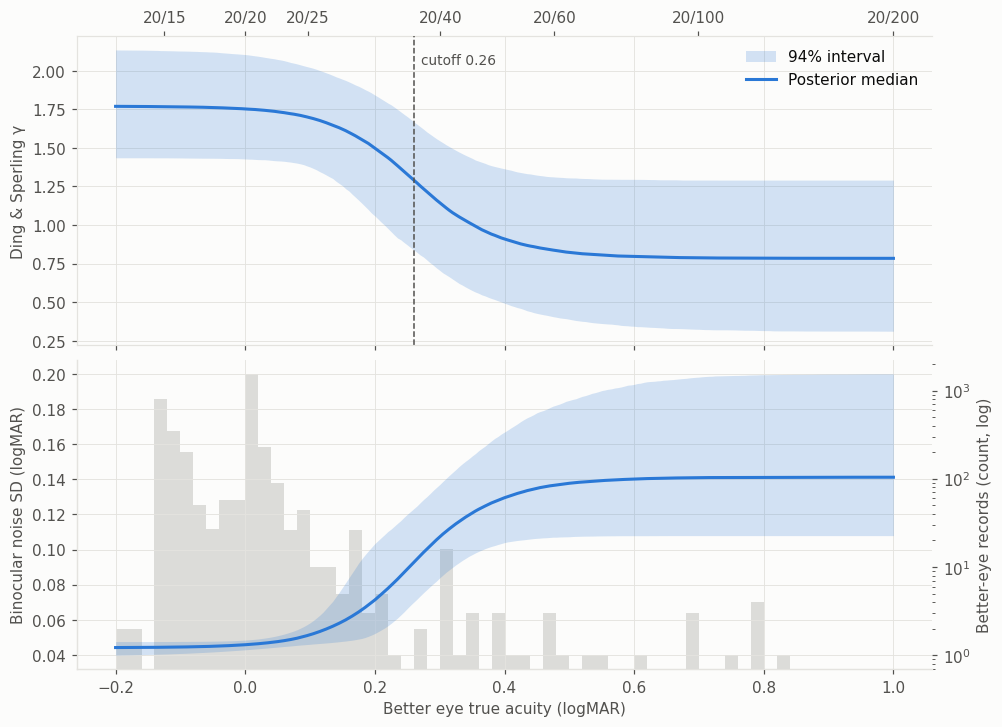

In [8]:
post = idata.posterior.stack(s=("chain", "draw"))
x = np.linspace(-0.2, 1.0, 241)
w = expit((x[:, None] - post["cutoff"].values) / post["tau"].values)
curves = {"Ding & Sperling γ": post["gamma_low"].values + (post["gamma_high"].values - post["gamma_low"].values) * w,
          "Binocular noise SD (logMAR)": post["sigma_bin_low"].values
          + (post["sigma_bin_high"].values - post["sigma_bin_low"].values) * w}
fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True, layout="constrained")
for ax, (label, c) in zip(axes, curves.items()):
    lo, med, hi = np.percentile(c, [3, 50, 97], axis=1)
    ax.fill_between(x, lo, hi, color=EMPIRICAL, alpha=0.2, lw=0, label="94% interval")
    ax.plot(x, med, color=EMPIRICAL, lw=2, label="Posterior median")
    ax.set_ylabel(label)
cut = float(post["cutoff"].median())
axes[0].axvline(cut, color=MUTED, ls="--", lw=1)
axes[0].text(cut + 0.01, axes[0].get_ylim()[1] * 0.95, f"cutoff {cut:.2f}", va="top", fontsize=9, color=MUTED)
axes[0].legend(frameon=False, loc="upper right")
rug = axes[1].twinx()
rug.hist(df["logmar_better"].clip(-0.2, 1.0), bins=np.arange(-0.2, 1.01, 0.02), color="#a3a29c", alpha=0.35)
rug.set_yscale("log")
rug.set_ylabel("Better-eye records (count, log)", color=MUTED)
rug.grid(False)
axes[1].set_zorder(rug.get_zorder() + 1)
axes[1].patch.set_visible(False)
axes[1].set_xlabel("Better eye true acuity (logMAR)")
top = axes[0].secondary_xaxis("top")
lines = [15, 20, 25, 40, 60, 100, 200]
top.set_xticks(np.log10(np.array(lines) / 20), [f"20/{v}" for v in lines])
plt.show()

## Binocular benefit by interocular difference

People with binocular better than 20/25, split by how much the two eyes differ. Model values are readings before recording, over 100 posterior draws. Records are in letter steps, so their bands are letters. Records understate the benefit: binocular readings beyond 20/15 are recorded as 20/15.

In [9]:
CUT = np.log10(25 / 20) - 1e-6   # strictly better than 20/25
bands = [(0, 0.005), (0.005, 0.01), (0.01, 0.02), (0.02, 0.03), (0.03, 0.05), (0.05, 0.1), (0, 0.1)]
bench_rng = np.random.default_rng(1)
picks = bench_rng.choice(post.sizes["s"], 100, replace=False)
res = {b: [] for b in bands}
for i in picks:
    q = {v: float(post[v].isel(s=i)) for v in ext.names(OPTIONS)}
    q["h_bare"] = q["h15"]
    s = ext.simulate(q, 100_000, bench_rng)
    better, diff = np.minimum(s.y_l, s.y_r), np.abs(s.y_l - s.y_r)
    for lo, hi in bands:
        k = (s.y_b < CUT) & (diff >= lo) & (diff < hi)
        res[(lo, hi)].append([(better - s.y_b)[k].mean(), ((s.y_l + s.y_r) / 2 - s.y_b)[k].mean(), k.mean()])
model_table = pd.DataFrame(
    {f"{lo:.3f}–{hi:.3f}": {"share of people": np.mean(r, 0)[2],
                           "over better eye": np.mean(r, 0)[0],
                           "over better eye 3%": np.percentile(r, 3, axis=0)[0],
                           "over better eye 97%": np.percentile(r, 97, axis=0)[0],
                           "over mean of eyes": np.mean(r, 0)[1]}
     for (lo, hi), r in ((b, np.array(v)) for b, v in res.items())}).T.round(3)
model_table.index.name = "model: eyes differ by"
model_table

,share of people,over better eye,over better eye 3%,over better eye 97%,over mean of eyes
model: eyes differ by,,,,,
0.000–0.005,0.144,0.035,0.032,0.038,0.036
0.005–0.010,0.136,0.032,0.029,0.036,0.036
0.010–0.020,0.219,0.029,0.026,0.032,0.036
0.020–0.030,0.139,0.024,0.021,0.027,0.036
0.030–0.050,0.121,0.019,0.016,0.022,0.038
0.050–0.100,0.120,0.009,0.007,0.012,0.045
0.000–0.100,0.878,0.026,0.023,0.029,0.038


In [10]:
good = df[df["logmar_binocular"] < CUT]
record_rows = {}
for lo, hi, name in [(-1, 1e-6, "0 (equal)"), (1e-6, 0.021, "one letter"), (0.021, 0.041, "two letters"),
                     (0.041, 0.061, "three letters"), (0.061, 0.1001, "0.06–0.1"), (-1, 0.1001, "all ≤ 0.1")]:
    d = good[(good["idiff"] > lo) & (good["idiff"] <= hi)]
    record_rows[name] = {"visits": len(d),
                         "over better eye": (d["logmar_better"] - d["logmar_binocular"]).mean(),
                         "over mean of eyes": ((d["logmar_better"] + d["logmar_worse"]) / 2 - d["logmar_binocular"]).mean()}
record_table = pd.DataFrame(record_rows).T.round(3)
record_table.index.name = "records: eyes differ by"
record_table

,visits,over better eye,over mean of eyes
records: eyes differ by,,,
0 (equal),1982.0,0.022,0.022
one letter,650.0,0.013,0.023
two letters,274.0,0.001,0.021
three letters,106.0,0.008,0.036
0.06–0.1,207.0,0.012,0.054
all ≤ 0.1,3219.0,0.018,0.025


## Posteriors of every parameter

Each panel is a parameter's posterior. Dashed lines mark the limits set in the fit, drawn only where the posterior comes close to one. A posterior pressed against a limit means the data want to go further, so read that value as a bound and not an estimate.

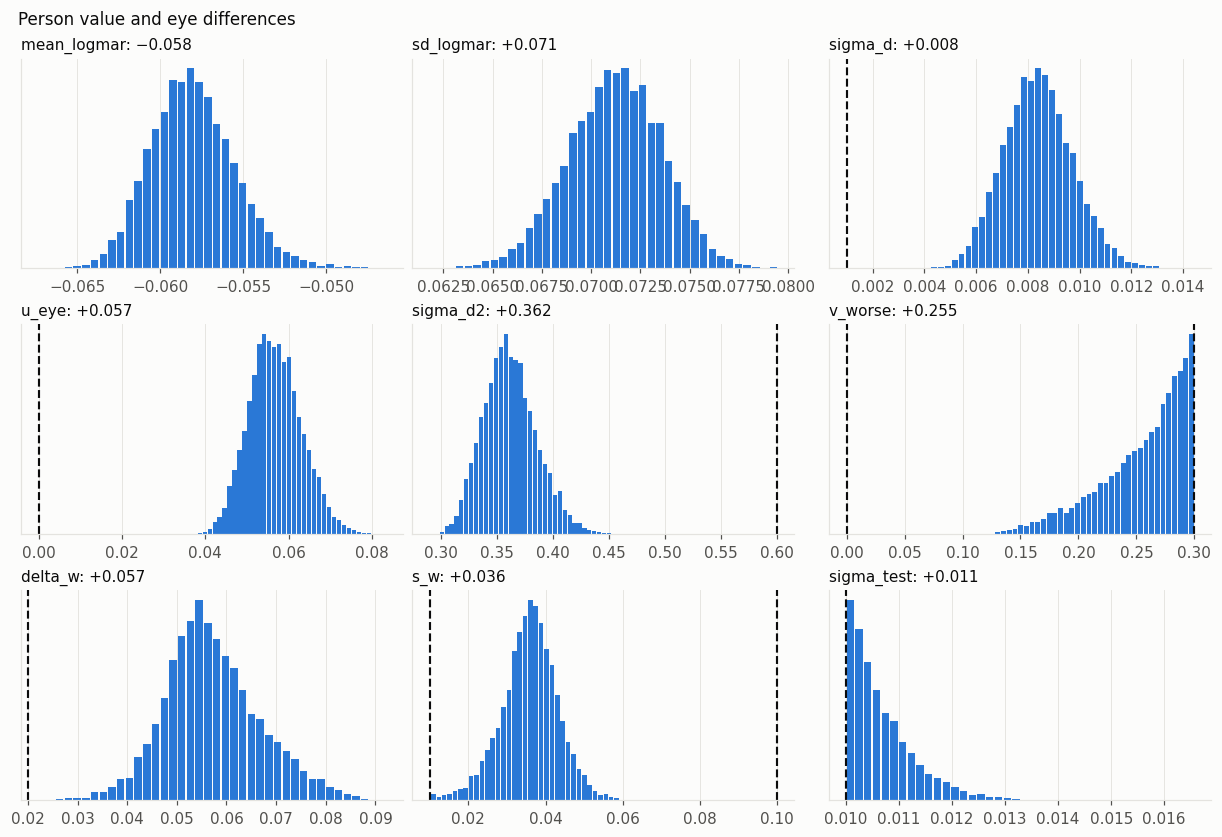

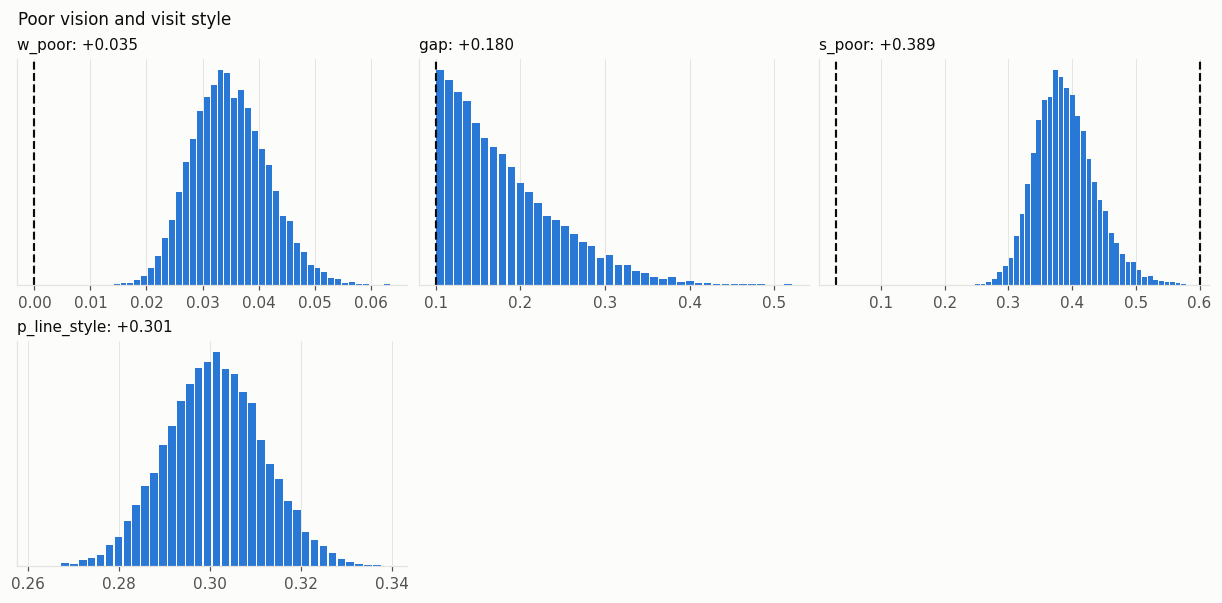

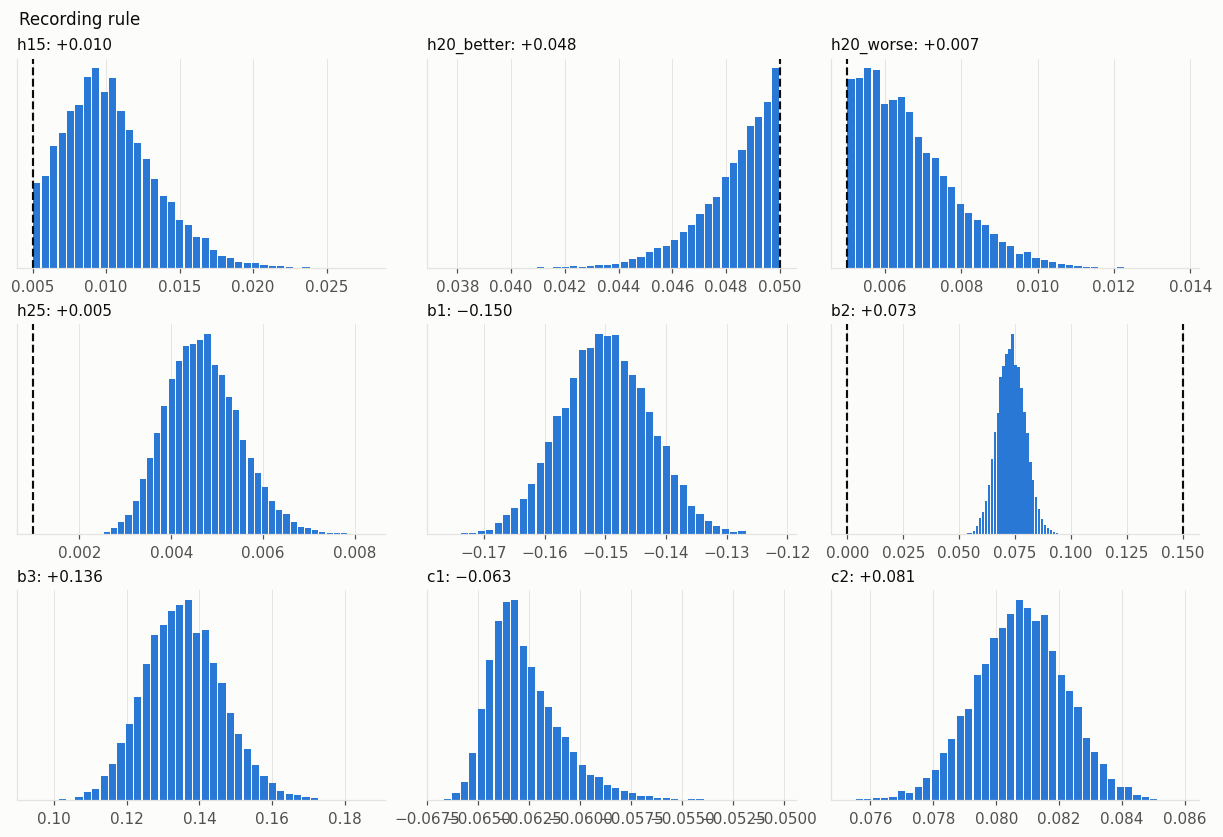

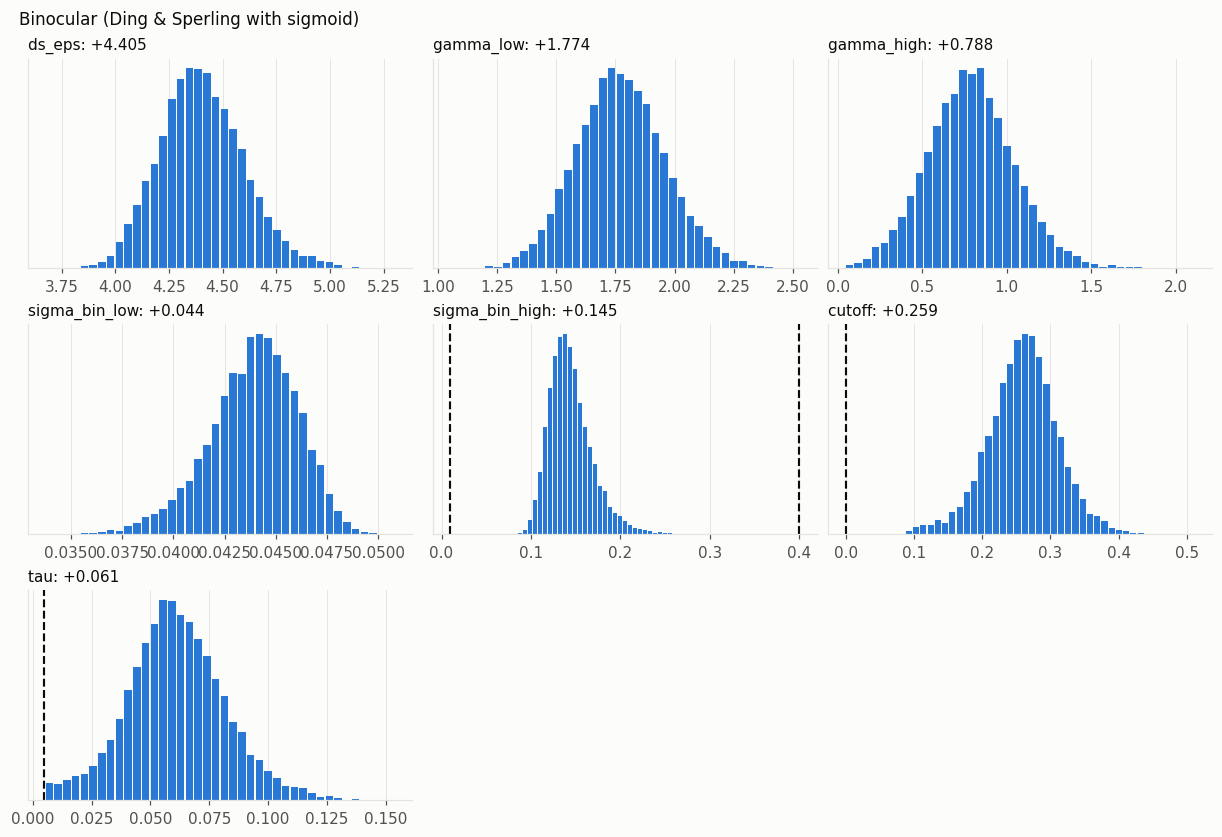

In [11]:
LIMITS = {"mean_logmar": (-0.25, 0.05), "sd_logmar": (0.01, 0.2), "sigma_d": (0.001, 0.04),
          "u_eye": (0, 0.95), "sigma_d2": (0.04, 0.6), "sigma_test": (0.01, 0.1), "ds_eps": (0.1, 50),
          "p_line_style": (0, 1), "w_poor": (0, 0.2), "gap": (0.1, 1.0), "s_poor": (0.03, 0.6),
          "h15": (0.005, 0.08), "h20_better": (0.005, 0.05), "h20_worse": (0.005, 0.05), "h25": (0.001, 0.04),
          "b1": (-0.25, 0), "b2": (0, 0.15), "v_worse": (0, 0.3), "delta_w": (0.02, 0.2), "s_w": (0.01, 0.1),
          "sigma_bin_low": (0.01, 0.15), "sigma_bin_high": (0.01, 0.4), "cutoff": (0, 1), "tau": (0.005, None)}

draws = lambda name: idata.posterior[name].values.ravel()


def posterior_grid(title, names):
    fig, axes = plt.subplots(3, 3, figsize=(11, 7.5), layout="constrained")
    fig.suptitle(title, x=0.01, ha="left", fontsize=11)
    for ax, name in zip(axes.ravel(), names):
        x = draws(name)
        ax.hist(x, bins=40, color=EMPIRICAL, rwidth=0.85)
        ax.set_title(f"{name}: {x.mean():+.3f}".replace("-", "−"), loc="left", fontsize=10)
        ax.set_yticks([])
        ax.grid(axis="y", visible=False)
        span = x.max() - x.min()
        for limit in LIMITS.get(name, ()):
            if limit is not None and x.min() - span <= limit <= x.max() + span:
                ax.axvline(limit, color=INK, lw=1.4, ls="--")
    for ax in axes.ravel()[len(names):]:
        ax.set_visible(False)
    plt.show()


posterior_grid("Person value and eye differences",
               ["mean_logmar", "sd_logmar", "sigma_d", "u_eye", "sigma_d2", "v_worse", "delta_w", "s_w", "sigma_test"])
posterior_grid("Poor vision and visit style", ["w_poor", "gap", "s_poor", "p_line_style"])
posterior_grid("Recording rule", ["h15", "h20_better", "h20_worse", "h25", "b1", "b2", "b3", "c1", "c2"])
posterior_grid("Binocular (Ding & Sperling with sigmoid)",
               ["ds_eps", "gamma_low", "gamma_high", "sigma_bin_low", "sigma_bin_high", "cutoff", "tau"])

## Trade-offs between parameters

Each dot is one posterior draw, and the upper triangle gives the correlation. Strong correlations mean the data fix a combination of the two parameters better than either alone.

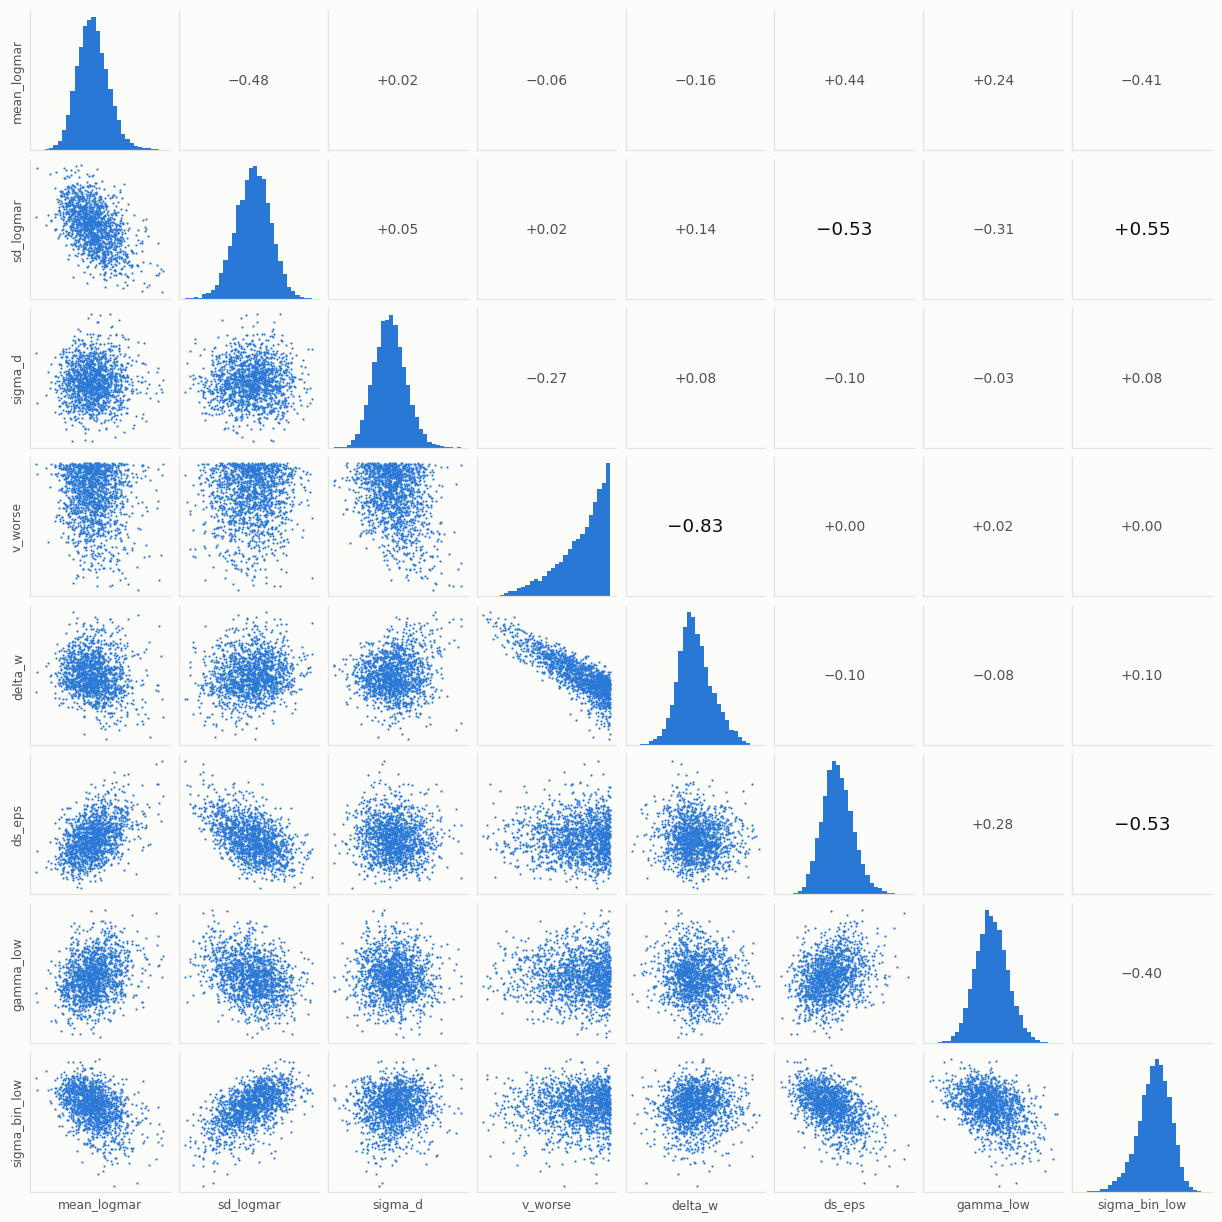

In [12]:
pair_names = ["mean_logmar", "sd_logmar", "sigma_d", "v_worse", "delta_w", "ds_eps", "gamma_low", "sigma_bin_low"]
pair_rng = np.random.default_rng(1)
pick = pair_rng.choice(len(draws("mean_logmar")), 1500, replace=False)
k = len(pair_names)
fig, axes = plt.subplots(k, k, figsize=(11, 11), layout="constrained")
for i, a in enumerate(pair_names):
    for j, b in enumerate(pair_names):
        ax = axes[i, j]
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        if i == j:
            ax.hist(draws(a), bins=30, color=EMPIRICAL)
        elif i > j:
            ax.scatter(draws(b)[pick], draws(a)[pick], s=2, color=EMPIRICAL, linewidths=0)
        else:
            r = np.corrcoef(draws(a), draws(b))[0, 1]
            ax.text(0.5, 0.5, f"{r:+.2f}".replace("-", "−"), transform=ax.transAxes, ha="center",
                    va="center", fontsize=12 if abs(r) >= 0.5 else 9, color=INK if abs(r) >= 0.5 else MUTED)
        if j == 0:
            ax.set_ylabel(a, fontsize=8)
        if i == k - 1:
            ax.set_xlabel(b, fontsize=8)
plt.show()

## Posteriors of the implied values

Implied readings of people outside the poor-vision component, from 300 posterior draws. The width of each posterior is the uncertainty within the fit. Your binocular target (−0.086, 0.095) is the dashed line on the binocular panels. The SDs include the few people with a large eye difference.

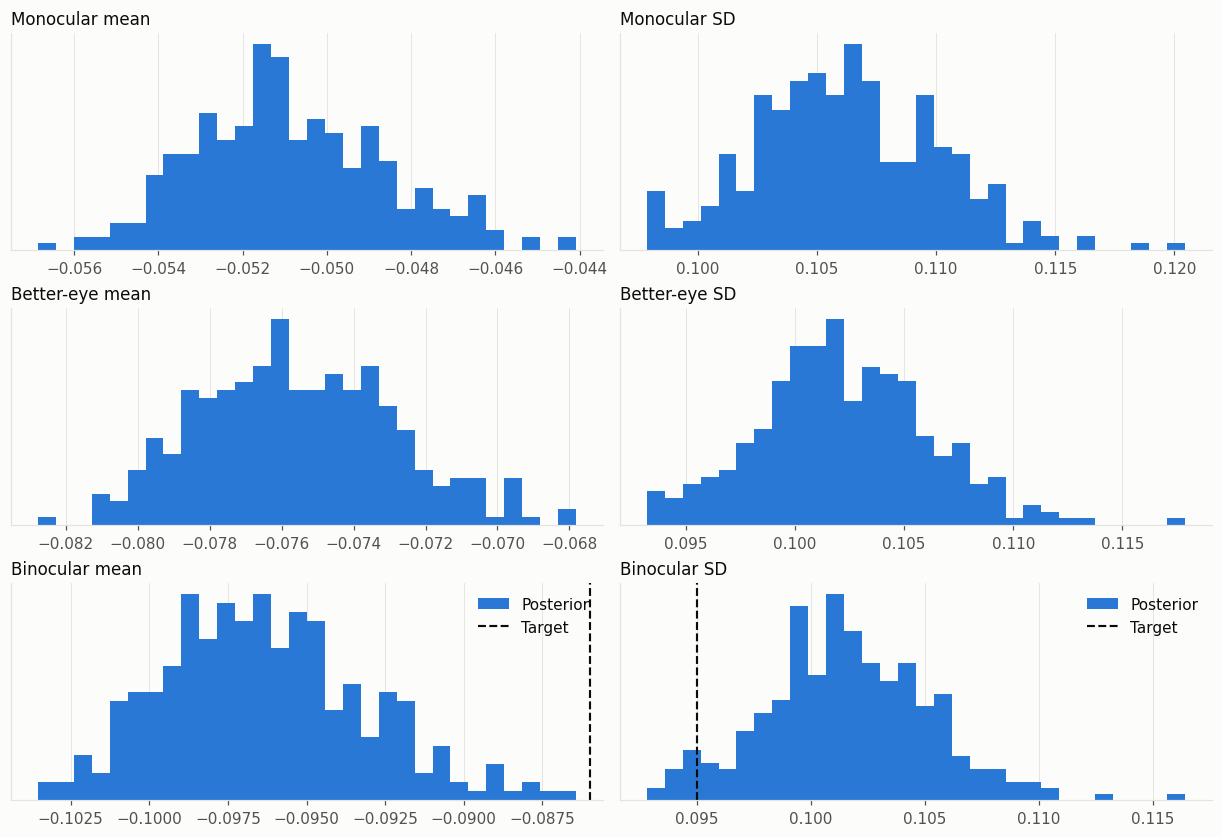

,mean,3%,97%
Monocular mean,-0.051,-0.055,-0.046
Monocular SD,0.106,0.099,0.114
Better-eye mean,-0.076,-0.080,-0.070
Better-eye SD,0.102,0.095,0.110
Binocular mean,-0.096,-0.102,-0.090
Binocular SD,0.102,0.095,0.109


In [13]:
value_rng = np.random.default_rng(2)
out = {k: [] for k in ["Monocular mean", "Monocular SD", "Better-eye mean", "Better-eye SD",
                       "Binocular mean", "Binocular SD"]}
for i in value_rng.choice(post.sizes["s"], 300, replace=False):
    q = {v: float(post[v].isel(s=i)) for v in ext.names(OPTIONS)}
    q["h_bare"] = q["h15"]
    s = ext.simulate(q, 50_000, value_rng)
    s = s[~s["poor"]]
    better = np.minimum(s.y_l, s.y_r)
    for name, v in [("Monocular", s.y_l), ("Better-eye", better), ("Binocular", s.y_b)]:
        out[f"{name} mean"].append(v.mean())
        out[f"{name} SD"].append(v.std())
values = {k: np.array(v) for k, v in out.items()}
targets = {"Binocular mean": -0.086, "Binocular SD": 0.095}
fig, axes = plt.subplots(3, 2, figsize=(11, 7.5), layout="constrained")
for ax, name in zip(axes.ravel(), values):
    ax.hist(values[name], bins=30, color=EMPIRICAL, label="Posterior")
    if name in targets:
        ax.axvline(targets[name], color=INK, lw=1.4, ls="--", label="Target")
        ax.legend(frameon=False, loc="upper right")
    ax.set_title(name, loc="left")
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
plt.show()

pd.DataFrame({"mean": {k: v.mean() for k, v in values.items()},
              "3%": {k: np.percentile(v, 3) for k, v in values.items()},
              "97%": {k: np.percentile(v, 97) for k, v in values.items()}}).round(3)

## What to take from this

- Eye differences come in three kinds: most people have near-identical eyes, a quarter have one eye about three letters worse, and a few have a large difference. With these the interocular-difference counts fit, from 0.1 to 0.5 logMAR.
- γ is about 1.75 for good better eyes and falls to about 0.8 below about 20/40; binocular noise rises from 0.044 to about 0.14. The low-vision half rests on few people.
- With equal eyes, binocular benefit is about 0.035 logMAR before recording. It shrinks against the better eye as the eyes differ, while staying about 0.036–0.038 against the mean of the eyes. Records show less because of the 20/15 ceiling.
- Binocular loss for good eyes with a worse partner is reproduced without a suppression term.
- Remaining misfits: too many binocular 20/20 plus in the model, too many eye pairs of bare 20/15 with bare 20/20, and too few of bare 20/20 with 20/20 minus. Recording style may vary within a visit.
- Better than 20/15 is implied, not measured. The chart appears to stop there, so that tail comes from the Normal assumption.